In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
from pathlib import Path
import random
import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
from PIL import Image

from crack_seg import config
from crack_seg.data_handlers.dataset_loaders import get_train_val_test_datasets
from crack_seg.data_handlers.transforms import val_transform
from crack_seg.utils.helpers import load_model
from crack_seg.utils.metrics import (
    centerline_buffer_metrics,
    crack_orientation_metrics,
    iou_score,
    dice_coefficient,
    _skeletonize,
)

# 1. Load Test Split (reusing test_ds if already loaded in notebook)
if "test_ds" not in globals():
    _, _, test_ds = get_train_val_test_datasets(
        train_transform=val_transform,
        val_transform=val_transform,
        dataset_names=config.DATASETS,
        data_root=config.DATA_ROOT,
        train_ratio=config.TRAIN_RATIO,
        val_ratio=config.VAL_RATIO,
        test_ratio=config.TEST_RATIO,
        seed=config.SPLIT_SEED,
        stratified=config.STRATIFIED_SPLIT,
    )


Dataset Splits Created (Total: 16089 samples):
  - Train:      11763 samples
  - Validation: 1600 samples
  - Test:       2726 samples



c:\Users\abinashm\AppData\Local\anaconda3\envs\computerVision\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Evaluating 10 random samples with cracks...



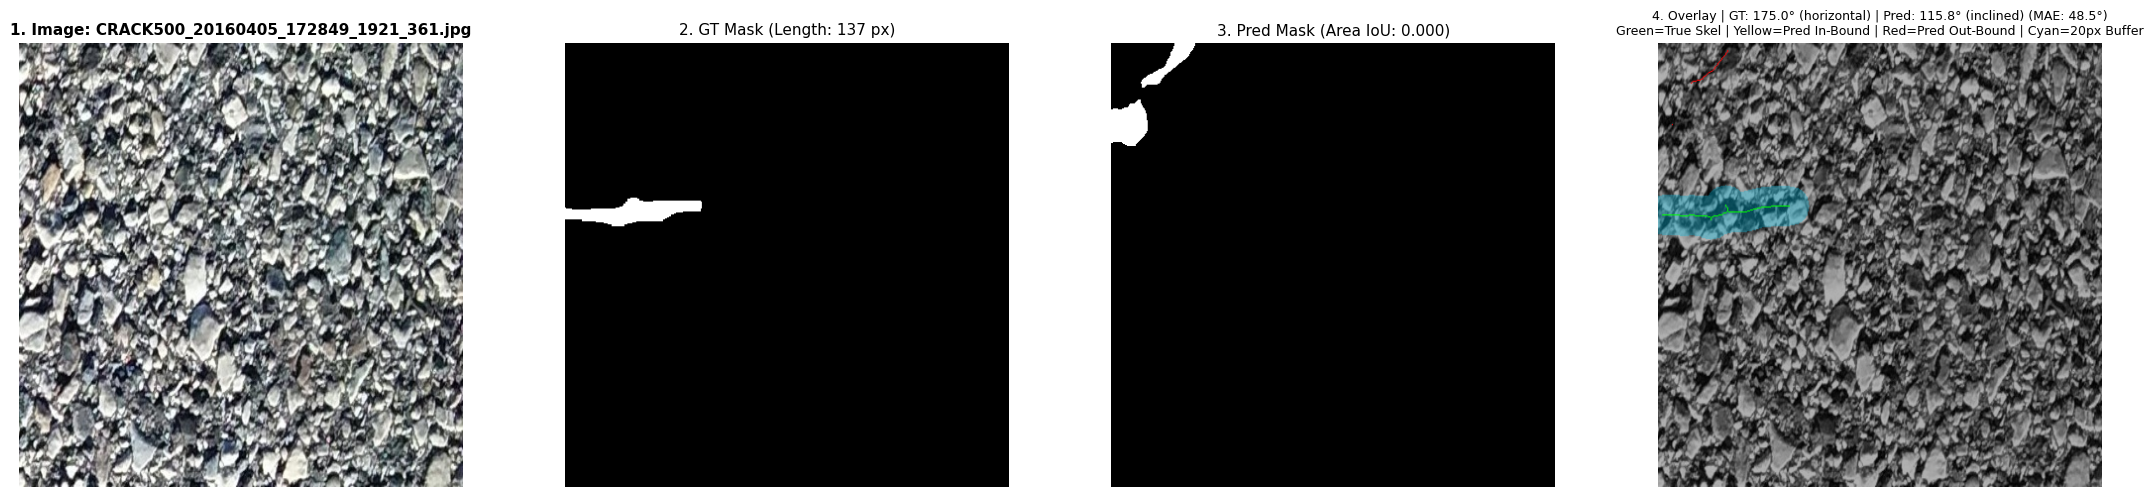

Sample [1/10]: CRACK500_20160405_172849_1921_361.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       137 px
  • Predicted Crack Length:  45 px
  • Pred in 20px Bound:      0 px (0.0%)
  • True Covered in 20px:    0 px (0.0%)
  • Centerline F1@20:        0.0000
  • Centerline IoU@20:       0.0000   [Standard Area IoU: 0.0000, Dice: 0.0000]
  • True Crack Orientation:  175.0° (horizontal)
  • Pred Crack Orientation:  115.8° (inclined)
  • Orientation MAE:         48.5°



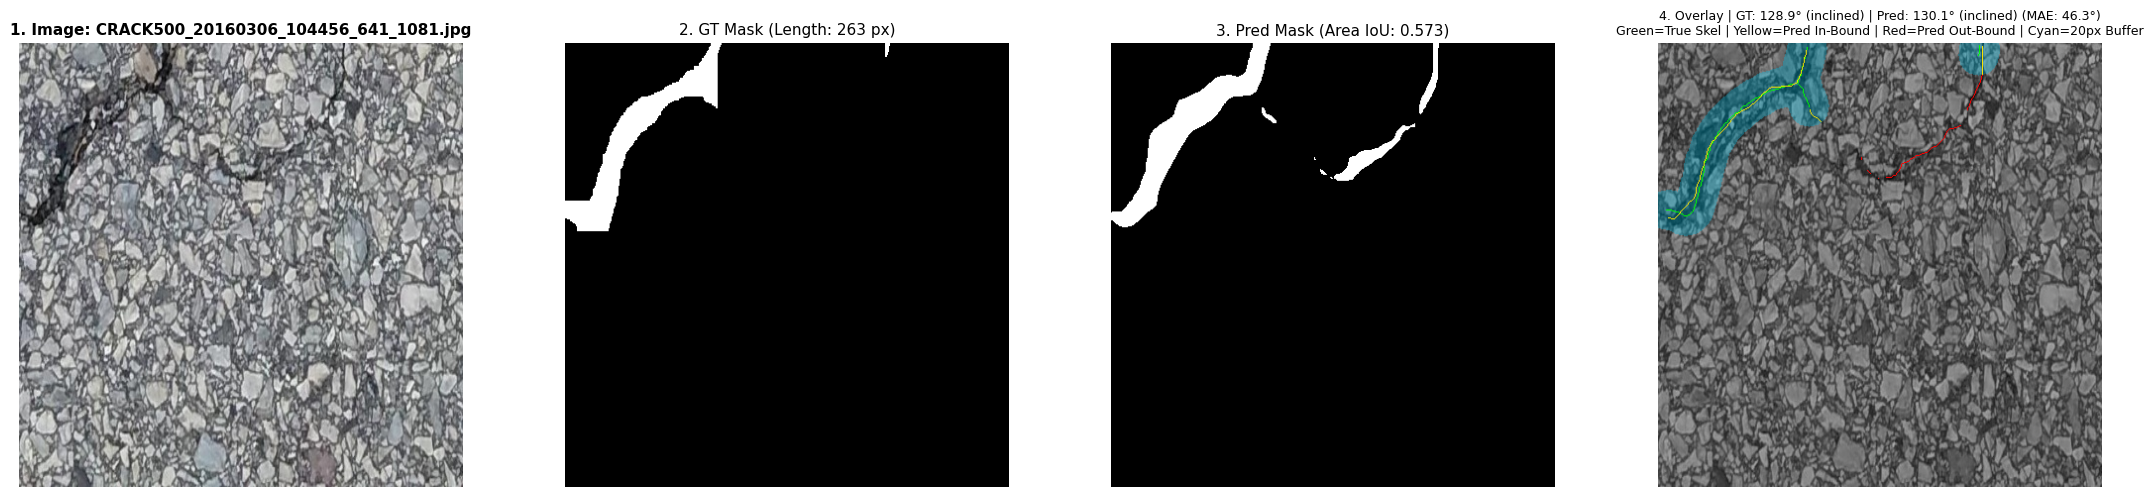

Sample [2/10]: CRACK500_20160306_104456_641_1081.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       263 px
  • Predicted Crack Length:  382 px
  • Pred in 20px Bound:      253 px (66.2%)
  • True Covered in 20px:    263 px (100.0%)
  • Centerline F1@20:        0.7969
  • Centerline IoU@20:       0.6454   [Standard Area IoU: 0.5727, Dice: 0.7283]
  • True Crack Orientation:  128.9° (inclined)
  • Pred Crack Orientation:  130.1° (inclined)
  • Orientation MAE:         46.3°



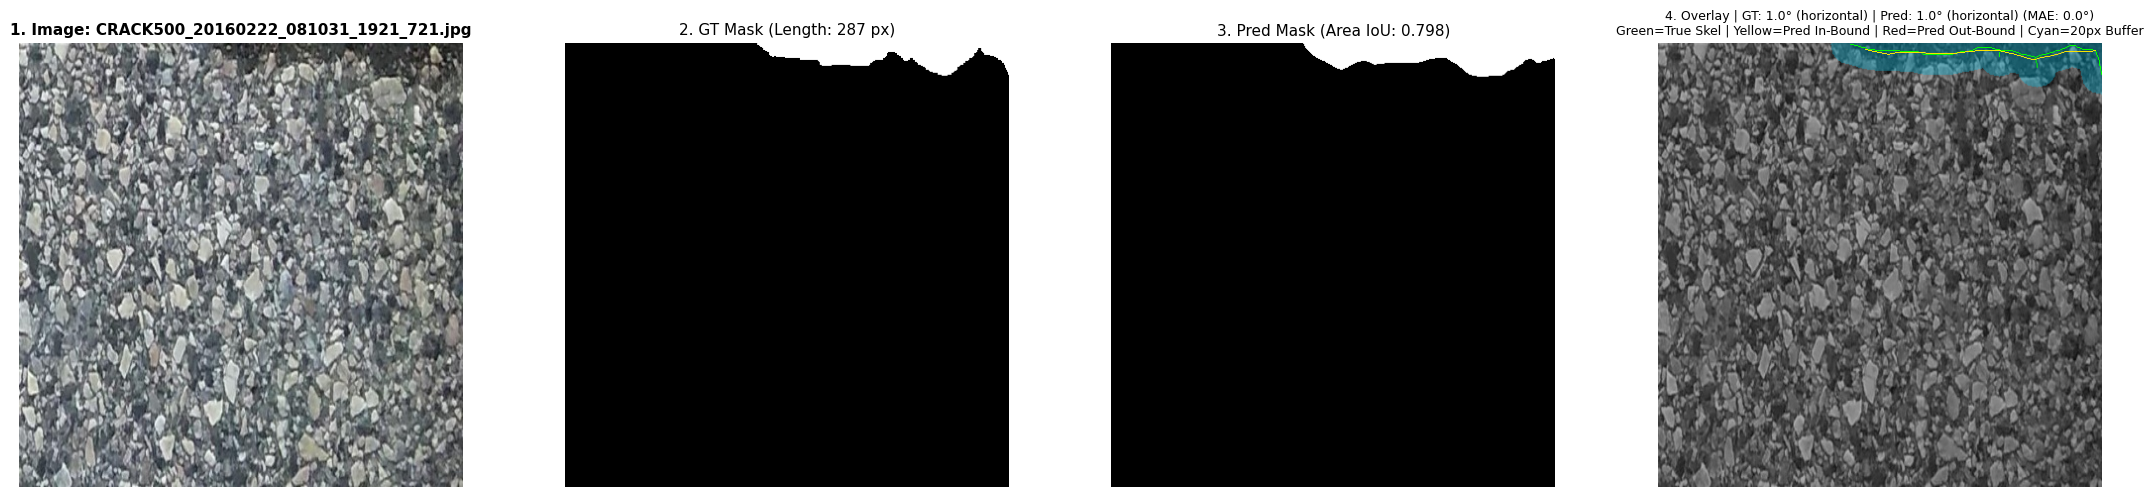

Sample [3/10]: CRACK500_20160222_081031_1921_721.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       287 px
  • Predicted Crack Length:  233 px
  • Pred in 20px Bound:      233 px (100.0%)
  • True Covered in 20px:    282 px (98.3%)
  • Centerline F1@20:        0.9912
  • Centerline IoU@20:       0.8118   [Standard Area IoU: 0.7984, Dice: 0.8879]
  • True Crack Orientation:  1.0° (horizontal)
  • Pred Crack Orientation:  1.0° (horizontal)
  • Orientation MAE:         0.0°



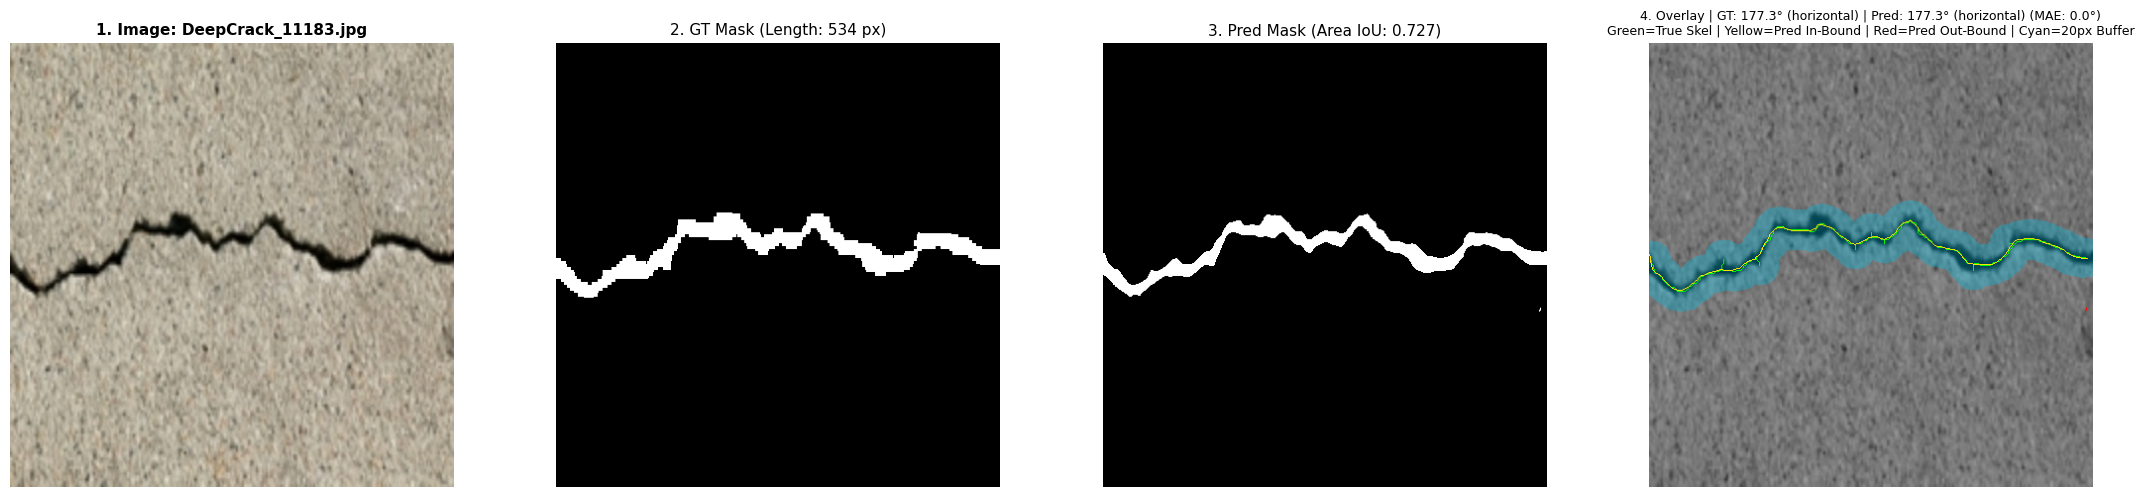

Sample [4/10]: DeepCrack_11183.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       534 px
  • Predicted Crack Length:  483 px
  • Pred in 20px Bound:      479 px (99.2%)
  • True Covered in 20px:    534 px (100.0%)
  • Centerline F1@20:        0.9958
  • Centerline IoU@20:       0.8903   [Standard Area IoU: 0.7266, Dice: 0.8417]
  • True Crack Orientation:  177.3° (horizontal)
  • Pred Crack Orientation:  177.3° (horizontal)
  • Orientation MAE:         0.0°



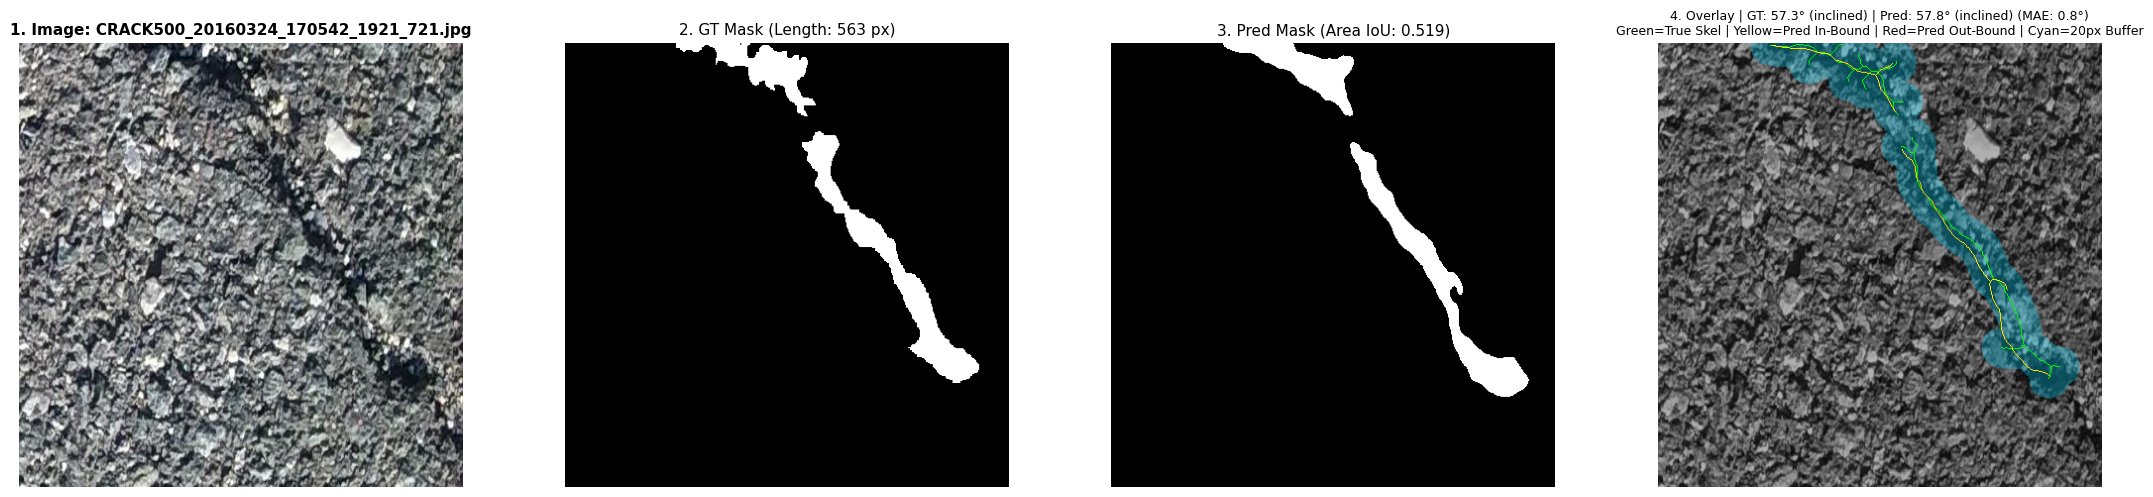

Sample [5/10]: CRACK500_20160324_170542_1921_721.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       563 px
  • Predicted Crack Length:  429 px
  • Pred in 20px Bound:      429 px (100.0%)
  • True Covered in 20px:    563 px (100.0%)
  • Centerline F1@20:        1.0000
  • Centerline IoU@20:       0.7620   [Standard Area IoU: 0.5191, Dice: 0.6834]
  • True Crack Orientation:  57.3° (inclined)
  • Pred Crack Orientation:  57.8° (inclined)
  • Orientation MAE:         0.8°



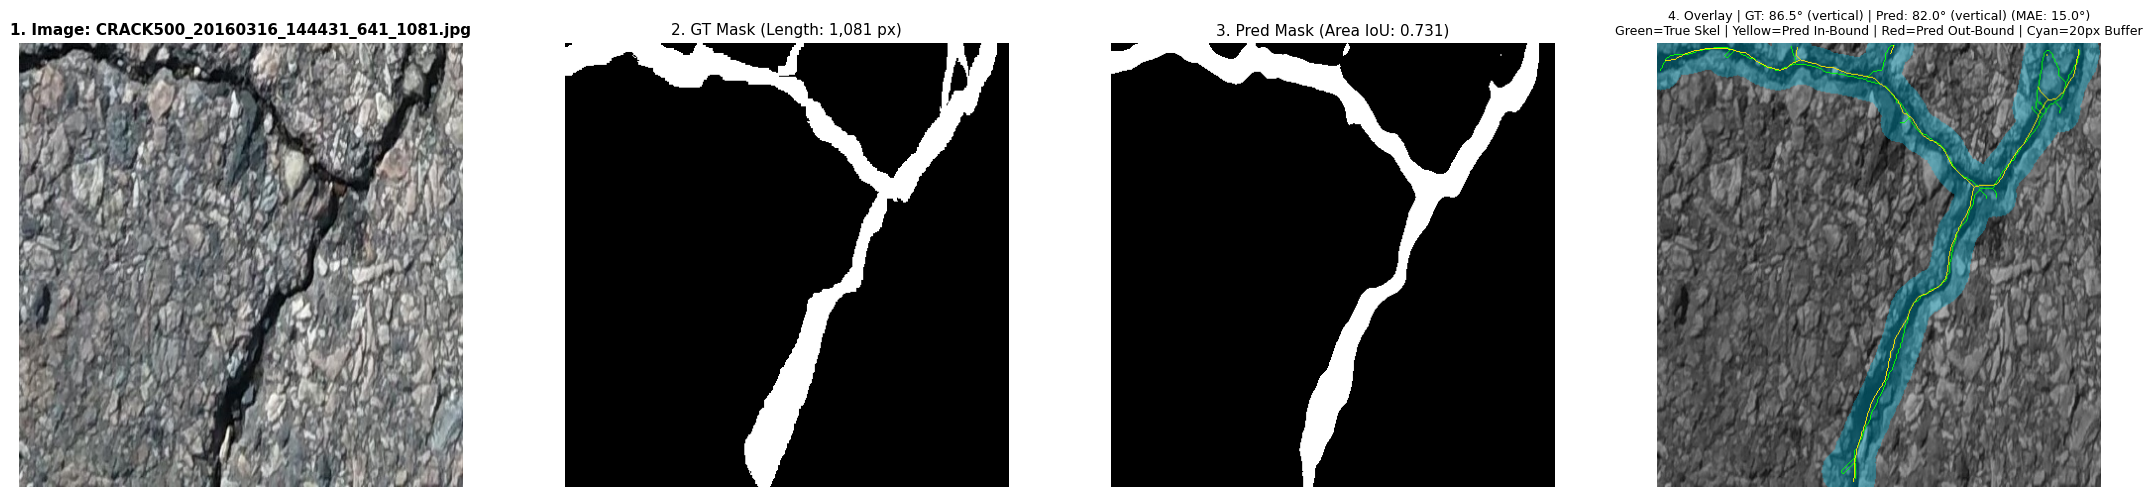

Sample [6/10]: CRACK500_20160316_144431_641_1081.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       1,081 px
  • Predicted Crack Length:  844 px
  • Pred in 20px Bound:      844 px (100.0%)
  • True Covered in 20px:    1,081 px (100.0%)
  • Centerline F1@20:        1.0000
  • Centerline IoU@20:       0.7808   [Standard Area IoU: 0.7313, Dice: 0.8448]
  • True Crack Orientation:  86.5° (vertical)
  • Pred Crack Orientation:  82.0° (vertical)
  • Orientation MAE:         15.0°



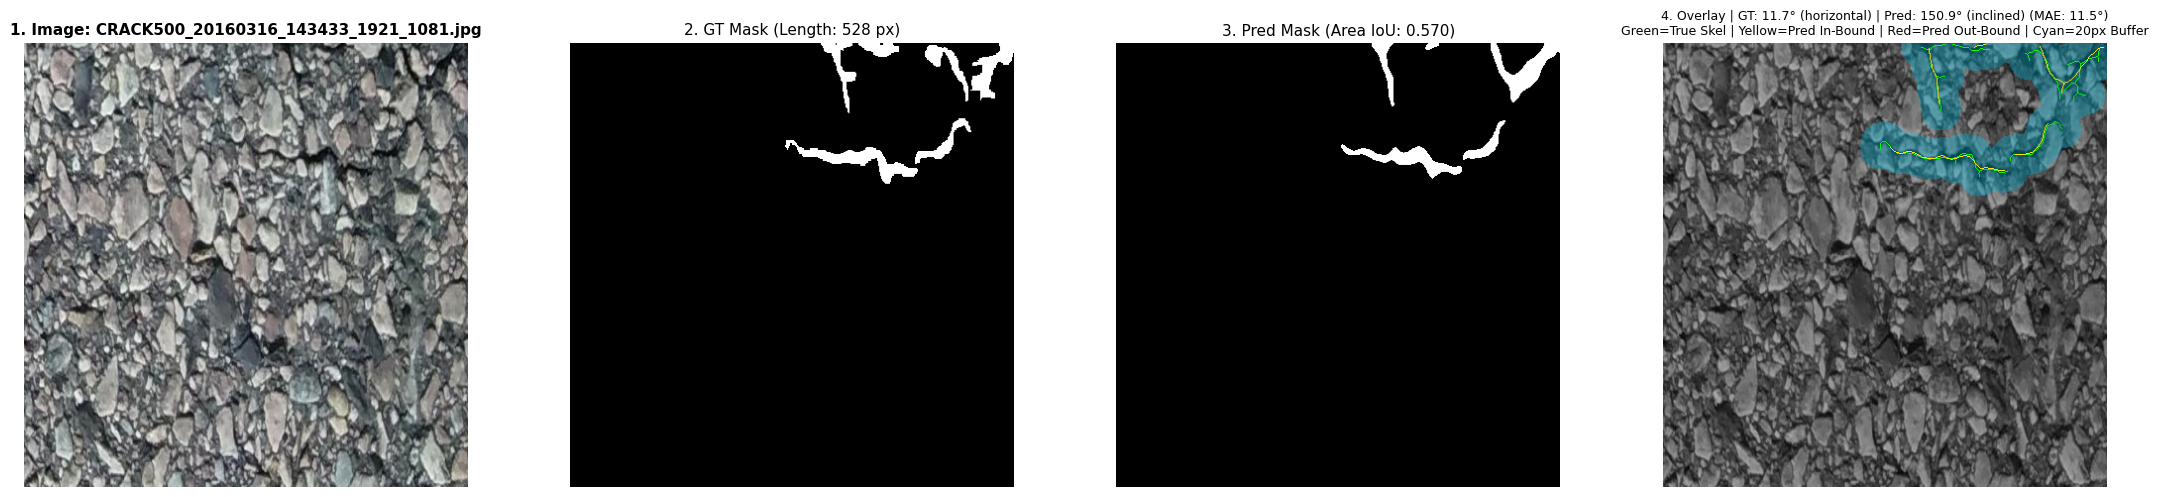

Sample [7/10]: CRACK500_20160316_143433_1921_1081.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       528 px
  • Predicted Crack Length:  330 px
  • Pred in 20px Bound:      330 px (100.0%)
  • True Covered in 20px:    523 px (99.1%)
  • Centerline F1@20:        0.9952
  • Centerline IoU@20:       0.6250   [Standard Area IoU: 0.5703, Dice: 0.7263]
  • True Crack Orientation:  11.7° (horizontal)
  • Pred Crack Orientation:  150.9° (inclined)
  • Orientation MAE:         11.5°



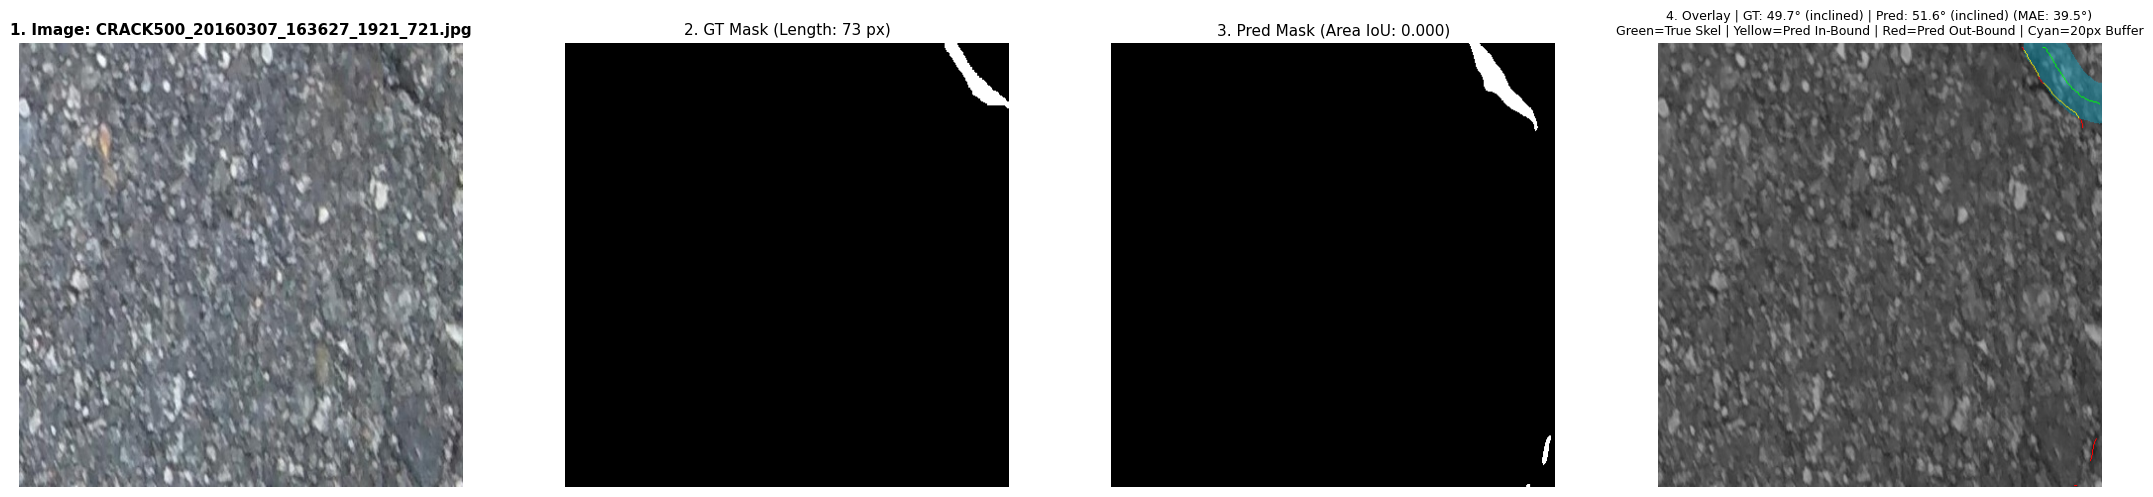

Sample [8/10]: CRACK500_20160307_163627_1921_721.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       73 px
  • Predicted Crack Length:  113 px
  • Pred in 20px Bound:      67 px (59.3%)
  • True Covered in 20px:    62 px (84.9%)
  • Centerline F1@20:        0.6983
  • Centerline IoU@20:       0.5000   [Standard Area IoU: 0.0000, Dice: 0.0000]
  • True Crack Orientation:  49.7° (inclined)
  • Pred Crack Orientation:  51.6° (inclined)
  • Orientation MAE:         39.5°



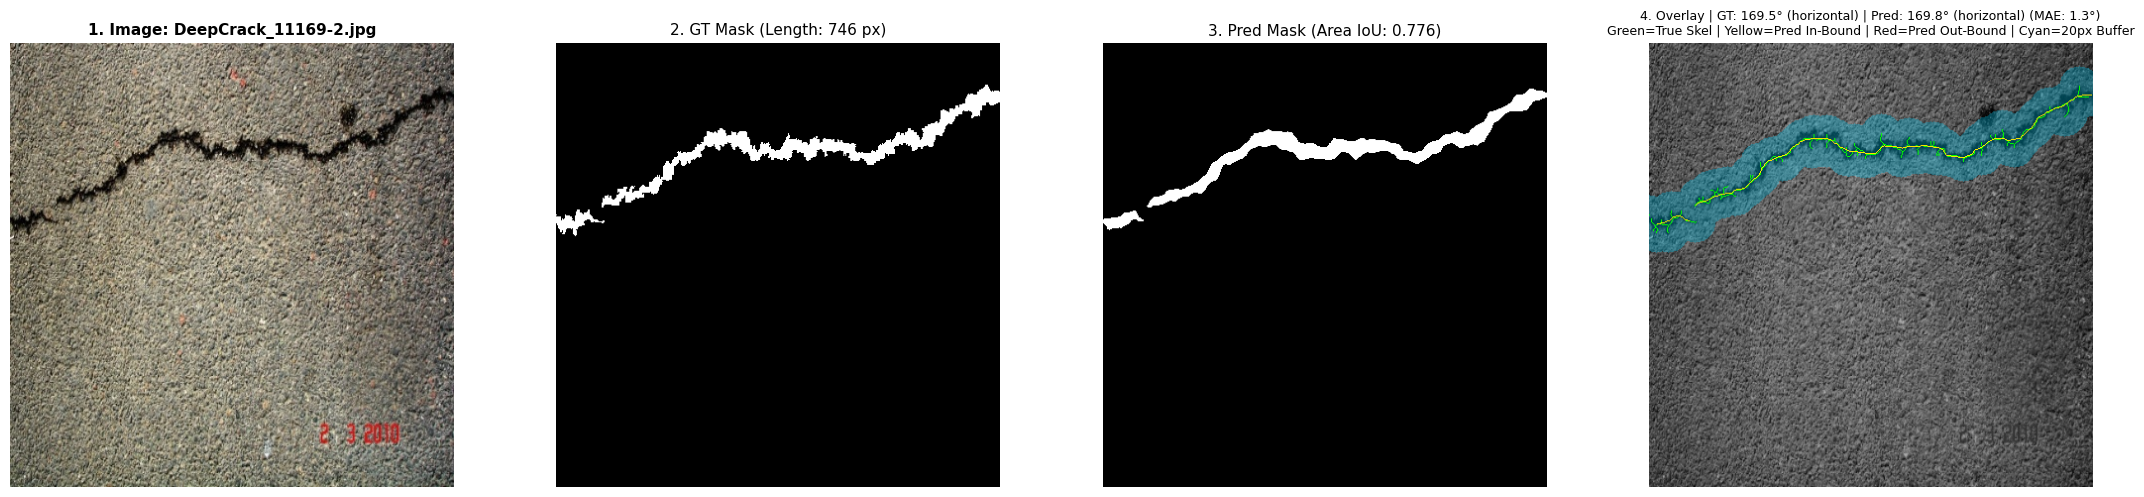

Sample [9/10]: DeepCrack_11169-2.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       746 px
  • Predicted Crack Length:  448 px
  • Pred in 20px Bound:      448 px (100.0%)
  • True Covered in 20px:    746 px (100.0%)
  • Centerline F1@20:        1.0000
  • Centerline IoU@20:       0.6005   [Standard Area IoU: 0.7764, Dice: 0.8741]
  • True Crack Orientation:  169.5° (horizontal)
  • Pred Crack Orientation:  169.8° (horizontal)
  • Orientation MAE:         1.3°



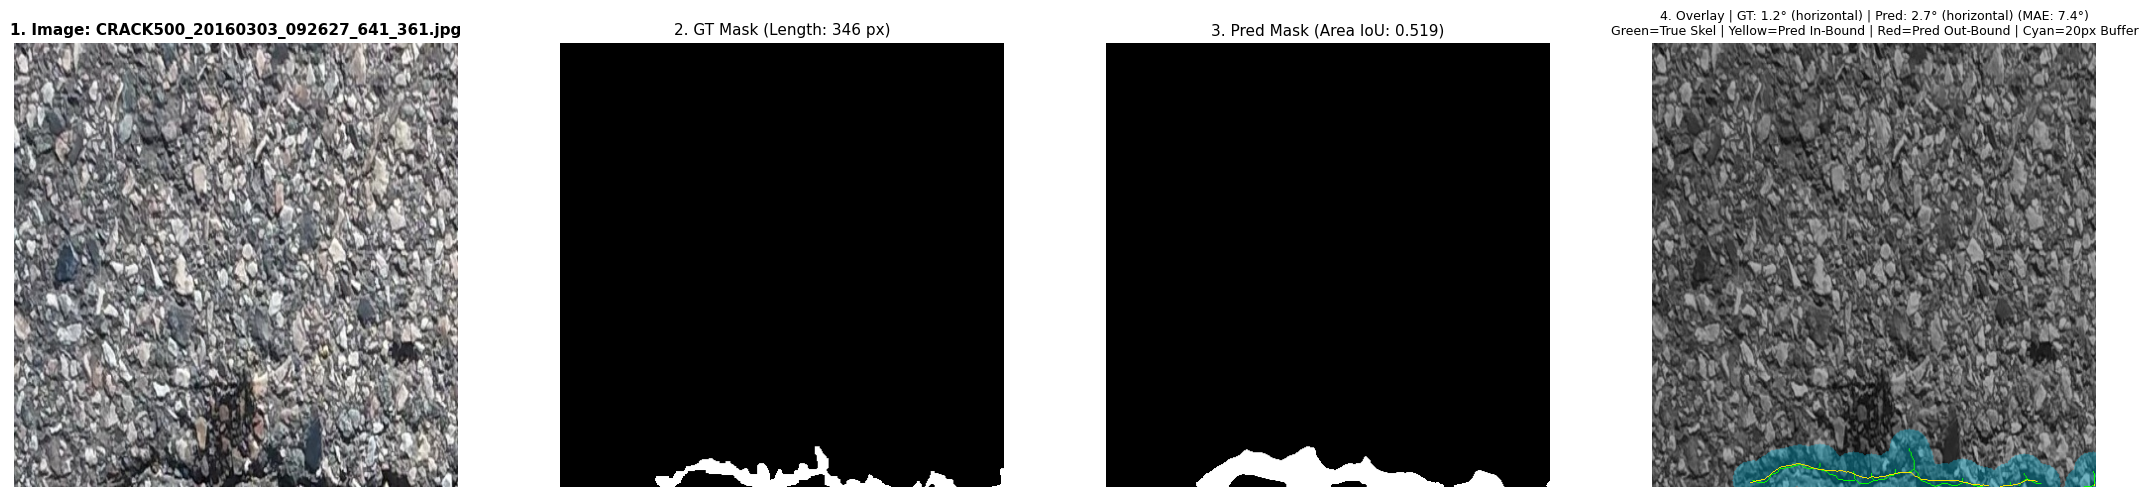

Sample [10/10]: CRACK500_20160303_092627_641_361.jpg
--------------------------------------------------------------------------------
  • True Crack Length:       346 px
  • Predicted Crack Length:  281 px
  • Pred in 20px Bound:      281 px (100.0%)
  • True Covered in 20px:    342 px (98.8%)
  • Centerline F1@20:        0.9942
  • Centerline IoU@20:       0.8121   [Standard Area IoU: 0.5188, Dice: 0.6832]
  • True Crack Orientation:  1.2° (horizontal)
  • Pred Crack Orientation:  2.7° (horizontal)
  • Orientation MAE:         7.4°


Sample                           GT Len   Pred Len Prec@20   Rec@20    F1@20     GT Angle         Pred Angle       Ori MAE    Area IoU 
---------------------------------------------------------------------------------------------------------------------------------------
CRACK500_20160405_172849_1921_361.jpg 137      45       0.0     % 0.0     % 0.0000    175.0° (horizontal) 115.8° (inclined) 48.5    °  0.0000   
CRACK500_20160306_104456_641_1081.jpg 263 

In [2]:
# 2. Load Model Checkpoint
ckpt_path = config.CHECKPOINT_DIR / "unet_CConCrack_NCCD-PF_Dataset_DeepCrack_CRACK500.pth"
eval_model = load_model("unet", str(ckpt_path), device=config.DEVICE)
eval_model.eval()

# 3. Select 10 random test samples that contain cracks
random.seed(42)  # For reproducible samples
cracked_indices = [
    idx for idx in range(min(600, len(test_ds)))
    if (np.array(Image.open(test_ds.samples[idx][1]).convert("L")) >= config.MASK_THRESHOLD).sum() > 400
]
selected_indices = random.sample(cracked_indices, min(10, len(cracked_indices)))

print(f"Evaluating {len(selected_indices)} random samples with cracks...\n")

# 4. Evaluate and visualize each sample
summary_rows = []

for i, sample_idx in enumerate(selected_indices, 1):
    image_tensor, target_tensor = test_ds[sample_idx]
    image_path, mask_path = test_ds.samples[sample_idx]
    
    # Model inference
    with torch.no_grad():
        out = eval_model(image_tensor.unsqueeze(0).to(config.DEVICE))
        pred_prob = torch.sigmoid(out).squeeze().cpu().numpy()
    
    # Original image & masks
    orig_img = Image.open(image_path).convert("RGB")
    orig_w, orig_h = orig_img.size
    
    gt_img = Image.open(mask_path).convert("L")
    gt_bin = (np.array(gt_img) >= config.MASK_THRESHOLD).astype(np.uint8)
    
    # Resize prediction probability to match original image dimensions
    pred_prob_resized = cv2.resize(pred_prob, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
    pred_bin = (pred_prob_resized >= 0.5).astype(np.uint8)
    
    # Calculate Centerline Buffer Metrics (20-pixel bound) & Orientation MAE
    metrics = centerline_buffer_metrics(pred_bin, gt_bin, tolerance_px=20.0)
    ori = crack_orientation_metrics(pred_bin, gt_bin)
    
    # Standard area-based metrics on the model resolution
    area_iou = iou_score(torch.from_numpy(pred_prob).unsqueeze(0), target_tensor).item()
    area_dice = dice_coefficient(torch.from_numpy(pred_prob).unsqueeze(0), target_tensor).item()
    
    # Skeletons for overlay
    gt_skel = _skeletonize(gt_bin)
    pred_skel = _skeletonize(pred_bin)
    
    # Exact Euclidean distance transform: 20px bound around ground-truth skeleton
    dist_to_gt = cv2.distanceTransform(1 - gt_skel, cv2.DIST_L2, 5)
    bound_20 = (dist_to_gt <= 20.0).astype(np.uint8)
    
    # Build 4th Panel: Centerline & 20px Buffer Visual Overlay
    gray_bg = cv2.cvtColor(np.array(orig_img), cv2.COLOR_RGB2GRAY)
    overlay = cv2.cvtColor((gray_bg * 0.7).astype(np.uint8), cv2.COLOR_GRAY2RGB)
    
    # Soft Cyan band: 20px Euclidean buffer around true crack
    buffer_mask = (bound_20 > 0)
    overlay[buffer_mask] = (overlay[buffer_mask] * 0.65 + np.array([0, 190, 230]) * 0.35).astype(np.uint8)
    
    # Bright Green: True crack skeleton
    overlay[gt_skel > 0] = [0, 255, 0]
    
    # Bright Yellow: Predicted crack skeleton inside the 20px bound (True Positive path)
    # Bright Red: Predicted crack skeleton outside the 20px bound (False Positive path)
    pred_in = np.logical_and(pred_skel, bound_20)
    pred_out = np.logical_and(pred_skel, ~bound_20.astype(bool))
    overlay[pred_in] = [255, 230, 0]
    overlay[pred_out] = [255, 0, 0]
    
    # 4-Column Side-by-Side Plot
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    
    # 1. Original Concrete Image
    axes[0].imshow(orig_img)
    axes[0].set_title(f"1. Image: {Path(image_path).name}", fontsize=11, fontweight="bold")
    axes[0].axis("off")
    
    # 2. Ground Truth Mask
    axes[1].imshow(gt_bin, cmap="gray")
    axes[1].set_title(f"2. GT Mask (Length: {metrics['gt_length_px']:,} px)", fontsize=11)
    axes[1].axis("off")
    
    # 3. Predicted Mask
    axes[2].imshow(pred_bin, cmap="gray")
    axes[2].set_title(f"3. Pred Mask (Area IoU: {area_iou:.3f})", fontsize=11)
    axes[2].axis("off")
    
    # Format orientations
    gt_ang_str = f"{ori['gt_angle_deg']:.1f}° ({ori['gt_category']})" if ori.get('gt_angle_deg') is not None else "N/A"
    pred_ang_str = f"{ori['pred_angle_deg']:.1f}° ({ori['pred_category']})" if ori.get('pred_angle_deg') is not None else "N/A"
    
    # 4. Centerline & 20px Buffer Overlay
    axes[3].imshow(overlay)
    axes[3].set_title(
        f"4. Overlay | GT: {gt_ang_str} | Pred: {pred_ang_str} (MAE: {ori['mae_deg']:.1f}°)\n"
        "Green=True Skel | Yellow=Pred In-Bound | Red=Pred Out-Bound | Cyan=20px Buffer",
        fontsize=9
    )
    axes[3].axis("off")
    
    plt.tight_layout()
    plt.show()
    
    # Print the requested metrics directly under each sample
    print("=" * 80)
    print(f"Sample [{i}/10]: {Path(image_path).name}")
    print("-" * 80)
    print(f"  • True Crack Length:       {metrics['gt_length_px']:,} px")
    print(f"  • Predicted Crack Length:  {metrics['pred_length_px']:,} px")
    print(f"  • Pred in 20px Bound:      {metrics['pred_len_in_bound_px']:,} px ({metrics['precision']*100:.1f}%)")
    print(f"  • True Covered in 20px:    {metrics['gt_len_covered_px']:,} px ({metrics['recall']*100:.1f}%)")
    print(f"  • Centerline F1@20:        {metrics['f1_score']:.4f}")
    print(f"  • Centerline IoU@20:       {metrics['iou']:.4f}   [Standard Area IoU: {area_iou:.4f}, Dice: {area_dice:.4f}]")
    print(f"  • True Crack Orientation:  {gt_ang_str}")
    print(f"  • Pred Crack Orientation:  {pred_ang_str}")
    print(f"  • Orientation MAE:         {ori['mae_deg']:.1f}°")
    print("=" * 80)
    print()
    
    summary_rows.append({
        "sample": Path(image_path).name,
        "gt_len": metrics["gt_length_px"],
        "pred_len": metrics["pred_length_px"],
        "prec20": metrics["precision"],
        "rec20": metrics["recall"],
        "f1_20": metrics["f1_score"],
        "iou_20": metrics["iou"],
        "area_iou": area_iou,
        "gt_angle": gt_ang_str,
        "pred_angle": pred_ang_str,
        "mae": ori["mae_deg"],
    })

# Final Summary Table across all 10 samples
print("\n" + "=" * 135)
print(f"{'Sample':<32} {'GT Len':<8} {'Pred Len':<8} {'Prec@20':<9} {'Rec@20':<9} {'F1@20':<9} {'GT Angle':<16} {'Pred Angle':<16} {'Ori MAE':<10} {'Area IoU':<9}")
print("-" * 135)
for s in summary_rows:
    print(f"{s['sample']:<32} {s['gt_len']:<8} {s['pred_len']:<8} {s['prec20']*100:<8.1f}% {s['rec20']*100:<8.1f}% {s['f1_20']:<9.4f} {s['gt_angle']:<16} {s['pred_angle']:<16} {s['mae']:<8.1f}°  {s['area_iou']:<9.4f}")
print("=" * 135)
